# 02 | Solar PPA Valuation & Risk Analysis

## Objective

This notebook develops a forward-looking valuation framework for a hypothetical **100 MWp pay-as-produced solar PPA in Germany**.

Notebook 1 showed that the market value of solar generation differs materially from annual baseload prices because of hourly production shape, negative-price exposure and price-volume correlation.

This notebook translates these historical findings into a five-year PPA valuation framework.

The analysis follows four steps:

1. Build a representative hourly P50 production profile for the solar asset.
2. Construct an hourly shaped forward-price curve from observable German baseload futures.
3. Estimate the forward market value of solar generation.
4. Derive a fair fixed PPA strike and assess its main risk sensitivities.

The reference PPA delivers from **2027 to 2031** and settles against the DE-LU electricity market.

## 1. Asset Definition

The reference asset is a hypothetical utility-scale photovoltaic plant located in the Leipzig area, Germany.

The objective is not to replicate a specific operating project, but to construct a realistic physical generation profile for PPA valuation.

| Parameter | Assumption |
|---|---|
| Location | Leipzig area, Germany |
| Coordinates | 51.341° N, 12.375° E |
| Installed capacity | 100 MWp |
| Technology | Crystalline-silicon PV |
| Mounting | Fixed tilt |
| Tilt | 35° |
| Orientation | South |
| System losses | 14% |
| Commercial operation date | 1 January 2027 |
| PPA structure | Pay-as-produced |
| PPA tenor | 5 years |
| Delivery period | 2027–2031 |
| Market reference | DE-LU |
| Settlement | Hourly |
| Currency | EUR |

Hourly solar generation is derived from PVGIS using 19 historical weather years from 2005 to 2023.

Historical weather observations are used to represent production uncertainty and are not interpreted as forecasts of specific future years.

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


# Reference solar asset and PPA assumptions
ASSET = {
    "location": "Leipzig, Germany",
    "latitude": 51.341,
    "longitude": 12.375,
    "capacity_mwp": 100,
    "tilt_deg": 35,
    "azimuth_deg": 0,
    "system_losses_pct": 14,
    "cod": "2027-01-01",
    "ppa_tenor_years": 5,
    "market": "DE-LU",
    "currency": "EUR"
}

ASSET

{'location': 'Leipzig, Germany',
 'latitude': 51.341,
 'longitude': 12.375,
 'capacity_mwp': 100,
 'tilt_deg': 35,
 'azimuth_deg': 0,
 'system_losses_pct': 14,
 'cod': '2027-01-01',
 'ppa_tenor_years': 5,
 'market': 'DE-LU',
 'currency': 'EUR'}

## 2. Solar Production Model

A pay-as-produced PPA settles on the electricity physically generated by the asset. The valuation therefore requires an hourly production profile rather than only an annual generation estimate.

PVGIS hourly simulations are used to model the output of the 100 MWp plant across **19 historical weather years (2005–2023)**.

Using multiple weather years allows the model to capture:

- seasonal solar production patterns;
- hourly production shape;
- interannual weather variability;
- downside and upside production scenarios.

The first step is to convert the raw PVGIS output into hourly electricity generation.

In [115]:
# Load the hourly PVGIS simulation
PVGIS_FILE = Path(
    "../data/raw/pvgis/"
    "Timeseries_51.341_12.375_SA3_100000kWp_crystSi_14_35deg_0deg_2005_2023.csv"
)

pvgis_raw = pd.read_csv(
    PVGIS_FILE,
    skiprows=10
)

# Keep only timestamp and simulated PV power
pv = pvgis_raw[["time", "P"]].copy()

# Remove the seven PVGIS documentation rows at the end of the file
pv = pv.iloc[:-7].copy()

# Rename and clean the two required variables
pv = pv.rename(columns={"P": "power_w"})

pv["power_w"] = pd.to_numeric(pv["power_w"])

pv["timestamp_utc"] = pd.to_datetime(
    pv["time"],
    format="%Y%m%d:%H%M",
    utc=True
)

pv = pv.drop(columns="time")

display(pv.head())

C:\Users\AGBULUT_A\AppData\Local\Temp\ipykernel_13672\1798102566.py:7: DtypeWarning: Columns (1: P) have mixed types. Specify dtype option on import or set low_memory=False.
  pvgis_raw = pd.read_csv(


,power_w,timestamp_utc
0,0.0,2005-01-01 00:10:00+00:00
1,0.0,2005-01-01 01:10:00+00:00
2,0.0,2005-01-01 02:10:00+00:00
3,0.0,2005-01-01 03:10:00+00:00
4,0.0,2005-01-01 04:10:00+00:00


### Hourly Generation

PVGIS reports simulated PV system output as hourly power $P_t$ in watts.

For each one-hour interval, electricity generation is therefore:

$$
Q_t = \frac{P_t}{10^6} \times 1\text{ h}
$$

where:

- $P_t$ is simulated PV output in watts;
- $Q_t$ is hourly electricity generation in MWh.

Because each interval represents one hour, the numerical MW value is equal to the MWh generated during that interval.

In [116]:
# Convert hourly PV output from W to MWh
pv["generation_mwh"] = (
    pv["power_w"] / 1_000_000
)

# Extract weather year
pv["weather_year"] = (
    pv["timestamp_utc"].dt.year
)

display(pv.head())

,power_w,timestamp_utc,generation_mwh,weather_year
0,0.0,2005-01-01 00:10:00+00:00,0.0,2005
1,0.0,2005-01-01 01:10:00+00:00,0.0,2005
2,0.0,2005-01-01 02:10:00+00:00,0.0,2005
3,0.0,2005-01-01 03:10:00+00:00,0.0,2005
4,0.0,2005-01-01 04:10:00+00:00,0.0,2005


### Annual Production Distribution

The 19 weather years are aggregated to measure annual generation variability and validate the physical model.

For each weather year, annual generation and capacity factor are calculated.

The capacity factor is defined as:

$$
CF_y =
\frac{E_y}
{P_{\text{installed}} \times H_y}
$$

where:

- $E_y$ is annual generation in MWh;
- $P_{\text{installed}}$ is installed capacity in MW;
- $H_y$ is the number of hours in the year.

In [117]:
annual_generation = (
    pv.groupby("weather_year")
    .agg(
        generation_mwh=("generation_mwh", "sum"),
        hours=("generation_mwh", "count")
    )
)

# Annual generation in GWh
annual_generation["generation_gwh"] = (
    annual_generation["generation_mwh"] / 1_000
)

# Annual capacity factor
annual_generation["capacity_factor_pct"] = (
    annual_generation["generation_mwh"]
    / (
        ASSET["capacity_mwp"]
        * annual_generation["hours"]
    )
    * 100
)

display(annual_generation[
    ["generation_gwh", "capacity_factor_pct"]
].round(2)
)

,generation_gwh,capacity_factor_pct
weather_year,,
2005,103.15,11.78
2006,107.62,12.29
2007,107.48,12.27
2008,101.75,11.58
2009,99.30,11.34
2010,99.60,11.37
2011,114.21,13.04
2012,105.24,11.98
2013,95.30,10.88


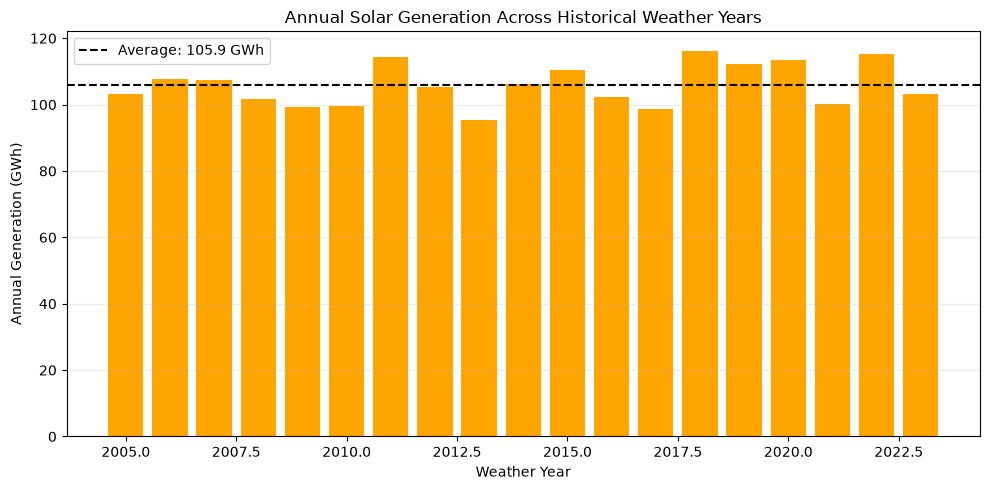

In [118]:
average_generation = (
    annual_generation["generation_gwh"].mean()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    annual_generation.index,
    annual_generation["generation_gwh"],
    color="orange"
)

ax.axhline(
    average_generation,
    color="black",
    linestyle="--",
    label=f"Average: {average_generation:.1f} GWh"
)

ax.set(
    title="Annual Solar Generation Across Historical Weather Years",
    xlabel="Weather Year",
    ylabel="Annual Generation (GWh)"
)

ax.grid(axis="y", alpha=0.25)
ax.legend()

fig.tight_layout()
plt.show()

## 3. P50 Production Profile

The historical weather years provide a distribution of possible annual generation outcomes.

For valuation, a single central production scenario is required. The **P50 annual generation** is defined as the median annual production across the 19 historical weather years:

$$
E_{P50}
=
\operatorname{Median}(E_y)
$$

where $E_y$ is the total annual generation for weather year $y$.

However, annual generation alone is not sufficient for a pay-as-produced PPA. The timing of production determines the market value of the electricity generated.

The P50 scenario therefore combines:

1. A central annual production level derived from the historical annual distribution.
2. A representative hourly solar shape derived from the median historical generation for each calendar hour.

The hourly profile is finally rescaled so that its total annual generation exactly matches the P50 annual energy target.

In [119]:
# Calculate the central annual production level
p50_generation_gwh = (
    annual_generation["generation_gwh"].median()
)

print(
    f"P50 annual generation: "
    f"{p50_generation_gwh:.2f} GWh"
)

P50 annual generation: 105.24 GWh


### Representative Hourly Shape

For each calendar hour, the median generation across the 19 historical weather years is calculated.

Using the median rather than a single historical year prevents the P50 profile from depending on one specific weather pattern.

February 29 is excluded to construct a standard **8,760-hour delivery year**.

In [120]:
# Extract calendar coordinates from each historical observation
pv["month"] = pv["timestamp_utc"].dt.month
pv["day"] = pv["timestamp_utc"].dt.day
pv["hour"] = pv["timestamp_utc"].dt.hour

# Remove February 29 to construct a standard 8,760-hour year
pv_standard = pv[
    ~(
        (pv["month"] == 2)
        & (pv["day"] == 29)
    )
].copy()

# Calculate median generation for each calendar hour
hourly_p50_profile = (
    pv_standard
    .groupby(["month", "day", "hour"])
    .agg(
        median_generation_mwh=(
            "generation_mwh",
            "median"
        )
    )
    .reset_index()
)

print(
    f"Hours in representative profile: "
    f"{len(hourly_p50_profile):,}"
)

Hours in representative profile: 8,760


In [121]:
# Annual energy implied by the hourly median shape
median_profile_gwh = (
    hourly_p50_profile["median_generation_mwh"].sum()
    / 1_000
)

# Scale the hourly shape to match the annual P50 target
p50_scaling_factor = (
    p50_generation_gwh
    / median_profile_gwh
)

hourly_p50_profile["p50_generation_mwh"] = (
    hourly_p50_profile["median_generation_mwh"]
    * p50_scaling_factor
)

# Validate the final profile
final_p50_gwh = (
    hourly_p50_profile["p50_generation_mwh"].sum()
    / 1_000
)

maximum_hourly_generation = (
    hourly_p50_profile["p50_generation_mwh"].max()
)

print(
    f"Median hourly shape: {median_profile_gwh:.2f} GWh"
)

print(
    f"P50 scaling factor: {p50_scaling_factor:.4f}"
)

print(
    f"Final P50 generation: {final_p50_gwh:.2f} GWh"
)

print(
    f"Maximum hourly generation: "
    f"{maximum_hourly_generation:.2f} MWh"
)

Median hourly shape: 107.14 GWh
P50 scaling factor: 0.9822
Final P50 generation: 105.24 GWh
Maximum hourly generation: 78.59 MWh


C:\Users\AGBULUT_A\AppData\Local\Temp\ipykernel_13672\1765092050.py:12: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  ).dt.dayofyear


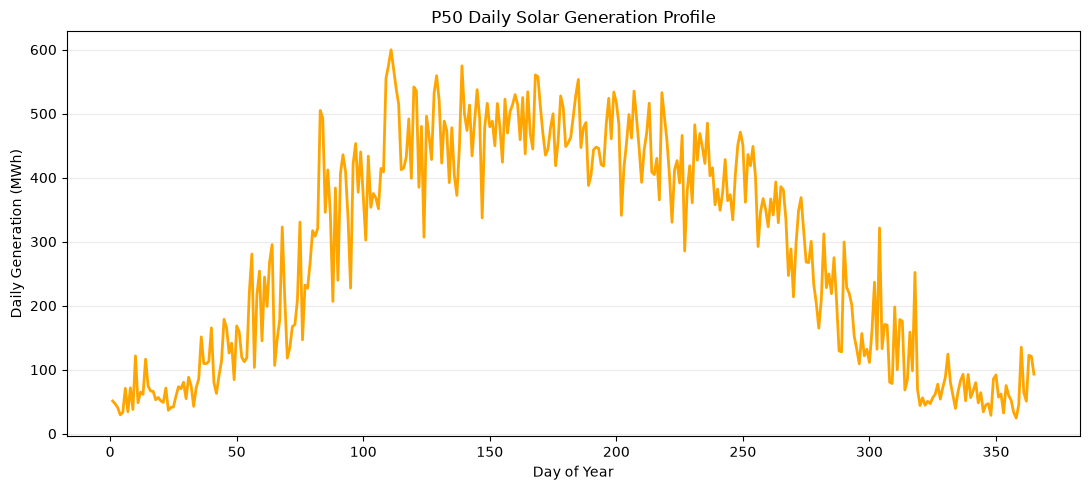

In [122]:
# Aggregate the hourly P50 profile to daily generation for visualization
p50_daily_profile = (
    hourly_p50_profile
    .assign(
        day_of_year=lambda x:
            pd.to_datetime(
                {
                    "year": 2027,
                    "month": x["month"],
                    "day": x["day"]
                }
            ).dt.dayofyear
    )
    .groupby("day_of_year")
    .agg(
        p50_generation_mwh=(
            "p50_generation_mwh",
            "sum"
        )
    )
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    p50_daily_profile.index,
    p50_daily_profile["p50_generation_mwh"],
    color="orange",
    linewidth=2
)

ax.set(
    title="P50 Daily Solar Generation Profile",
    xlabel="Day of Year",
    ylabel="Daily Generation (MWh)"
)

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

## 4. Forward Market Curve

The P50 profile defines when and how much electricity the solar asset is expected to generate.

The next input is the market value of future electricity.

The five-year PPA delivers from 2027 to 2031. German Power Base annual futures are therefore used as observable market references for each delivery year.

| Product | Delivery Year | Settlement Price |
|---|---:|---:|
| Cal-27 | 2027 | 138.93 EUR/MWh |
| Cal-28 | 2028 | 98.55 EUR/MWh |
| Cal-29 | 2029 | 85.54 EUR/MWh |
| Cal-30 | 2030 | 79.25 EUR/MWh |
| Cal-31 | 2031 | 75.52 EUR/MWh |

**Source:** Energy-Charts, based on EEX German Power Base Year Futures settlement prices, market snapshot observed on 18 November 2026.

The curve represents a market snapshot observed on **18 November 2026**.

These prices represent the value of constant baseload delivery. They cannot yet be applied directly to the solar production profile because solar generation is concentrated in specific hours of the day and seasons of the year.

In [123]:
# German Power Base annual futures
# Market snapshot: 18 November 2026

forward_curve = pd.DataFrame({
    "delivery_year": [
        2027,
        2028,
        2029,
        2030,
        2031
    ],
    "forward_price_eur_mwh": [
        138.93,
        98.55,
        85.54,
        79.25,
        75.52
    ]
})

display(forward_curve)

,delivery_year,forward_price_eur_mwh
0,2027,138.93
1,2028,98.55
2,2029,85.54
3,2030,79.25
4,2031,75.52


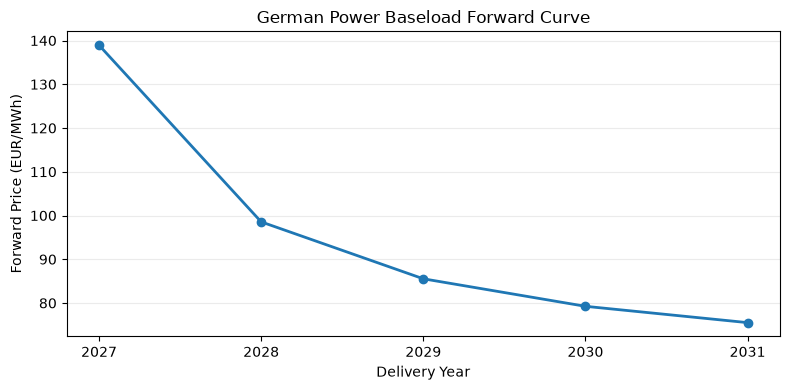

In [124]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    forward_curve["delivery_year"],
    forward_curve["forward_price_eur_mwh"],
    marker="o",
    linewidth=2
)

ax.set(
    title="German Power Baseload Forward Curve",
    xlabel="Delivery Year",
    ylabel="Forward Price (EUR/MWh)",
    xticks=forward_curve["delivery_year"]
)

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

The forward curve is strongly downward sloping over the PPA horizon, decreasing from **138.93 EUR/MWh in 2027 to 75.52 EUR/MWh in 2031**.

This backwardation materially affects the economics of a fixed-price PPA because the contract must convert a declining sequence of annual market values into a single strike price.

However, the annual baseload forwards still need to be shaped before they can be combined with the hourly solar production profile.

## 5. Forward Price Shaping

Annual baseload futures provide observable market prices for constant electricity delivery, but they do not contain the hourly price structure required to value a pay-as-produced solar profile.

A relative historical price shape is therefore estimated from DE-LU day-ahead prices.

The base case uses observations from **2023 to 2025** because these years better represent the recent solar-cannibalisation regime identified in Notebook 1. Earlier years, particularly the exceptional 2022 energy-crisis period, are excluded from the base calibration.

Prices are grouped by month and hour of day, producing:

$$
12 \text{ months} \times 24 \text{ hours}
=
288 \text{ price buckets}
$$

For each month $m$ and hour $h$, the raw price factor is:

$$
SF_{m,h}^{raw}
=
\frac{\overline{P}_{m,h}}
{\overline{P}}
$$

where:

- $\overline{P}_{m,h}$ is the average historical price for month $m$ and hour $h$;
- $\overline{P}$ is the overall historical average price during the calibration period.

The factors are subsequently mapped onto a standard 8,760-hour year and normalised so that their annual hourly average equals one.

For delivery year $y$ and hour $t$, the shaped forward price is:

$$
F_{y,t}^{shaped}
=
F_y^{base} \times SF_t
$$

This preserves the observable annual baseload forward level while introducing an illustrative seasonal and intraday price structure.

The resulting hourly curves are modelling assumptions and should not be interpreted as directly observable hourly forward prices.

In [125]:
# Load the cleaned hourly DE-LU price history from Notebook 1
PRICE_HISTORY_FILE = Path(
    "../data/processed/de_lu_hourly_prices_2021_2025.csv"
)

price_history = pd.read_csv(
    PRICE_HISTORY_FILE,
    parse_dates=["start_date"]
)

# Use the recent 2023-2025 market regime for the base calibration
recent_prices = price_history[
    price_history["start_date"].dt.year >= 2023
].copy()

# Extract calendar coordinates
recent_prices["month"] = recent_prices["start_date"].dt.month
recent_prices["hour"] = recent_prices["start_date"].dt.hour

print(
    f"Calibration observations: "
    f"{len(recent_prices):,}"
)

print(
    f"Calibration period: "
    f"{recent_prices['start_date'].min():%Y-%m-%d} to "
    f"{recent_prices['start_date'].max():%Y-%m-%d}"
)

Calibration observations: 26,304
Calibration period: 2023-01-01 to 2025-12-31


In [126]:
# Calculate the average historical price for each month-hour bucket
month_hour_shape = (
    recent_prices
    .groupby(["month", "hour"])
    .agg(
        historical_price_eur_mwh=(
            "price_eur_mwh",
            "mean"
        )
    )
    .reset_index()
)

print(
    f"Month-hour price buckets: "
    f"{len(month_hour_shape)}"
)

display(month_hour_shape.head())

Month-hour price buckets: 288


,month,hour,historical_price_eur_mwh
0,1,0,80.208710
1,1,1,75.596774
2,1,2,73.374731
3,1,3,70.091720
4,1,4,71.038387


In [127]:
# Calculate the overall average price during the calibration period
historical_average_price = (
    recent_prices["price_eur_mwh"].mean()
)

# Express each month-hour price relative to the overall average
month_hour_shape["raw_shape_factor"] = (
    month_hour_shape["historical_price_eur_mwh"]
    / historical_average_price
)

print(
    f"2023-2025 historical average price: "
    f"{historical_average_price:.2f} EUR/MWh"
)

display(month_hour_shape.head())

2023-2025 historical average price: 87.66 EUR/MWh


,month,hour,historical_price_eur_mwh,raw_shape_factor
0,1,0,80.208710,0.914983
1,1,1,75.596774,0.862372
2,1,2,73.374731,0.837024
3,1,3,70.091720,0.799573
4,1,4,71.038387,0.810372


In [128]:
# Create a standard 8,760-hour calendar year
standard_year = pd.DataFrame({
    "timestamp": pd.date_range(
        start="2027-01-01 00:00",
        end="2027-12-31 23:00",
        freq="h"
    )
})

# Extract calendar coordinates
standard_year["month"] = standard_year["timestamp"].dt.month
standard_year["day"] = standard_year["timestamp"].dt.day
standard_year["hour"] = standard_year["timestamp"].dt.hour

# Assign the relevant month-hour price factor to each hour
standard_year = standard_year.merge(
    month_hour_shape[
        [
            "month",
            "hour",
            "raw_shape_factor"
        ]
    ],
    on=["month", "hour"],
    how="left",
    validate="many_to_one"
)

print(
    f"Hours in standard year: "
    f"{len(standard_year):,}"
)

print(
    f"Missing shape factors: "
    f"{standard_year['raw_shape_factor'].isna().sum()}"
)

Hours in standard year: 8,760
Missing shape factors: 0


### Standard-Year Mapping and Normalisation

The 288 month-hour price buckets are mapped onto every hour of a standard non-leap year.

A second normalisation is performed after this mapping because calendar months contain different numbers of days. For example, January represents 744 hours, while February represents 672 hours in a standard year.

The final factors satisfy:

$$
\frac{1}{8760}
\sum_{t=1}^{8760}
SF_t
=
1
$$

This condition ensures that shaping does not create or destroy annual baseload value.


In [129]:
# Normalise factors so that their 8,760-hour average equals one
standard_year["shape_factor"] = (
    standard_year["raw_shape_factor"]
    / standard_year["raw_shape_factor"].mean()
)

print(
    f"Average normalised shape factor: "
    f"{standard_year['shape_factor'].mean():.6f}"
)

print(
    f"Minimum shape factor: "
    f"{standard_year['shape_factor'].min():.3f}"
)

print(
    f"Maximum shape factor: "
    f"{standard_year['shape_factor'].max():.3f}"
)

Average normalised shape factor: 1.000000
Minimum shape factor: 0.139
Maximum shape factor: 2.140


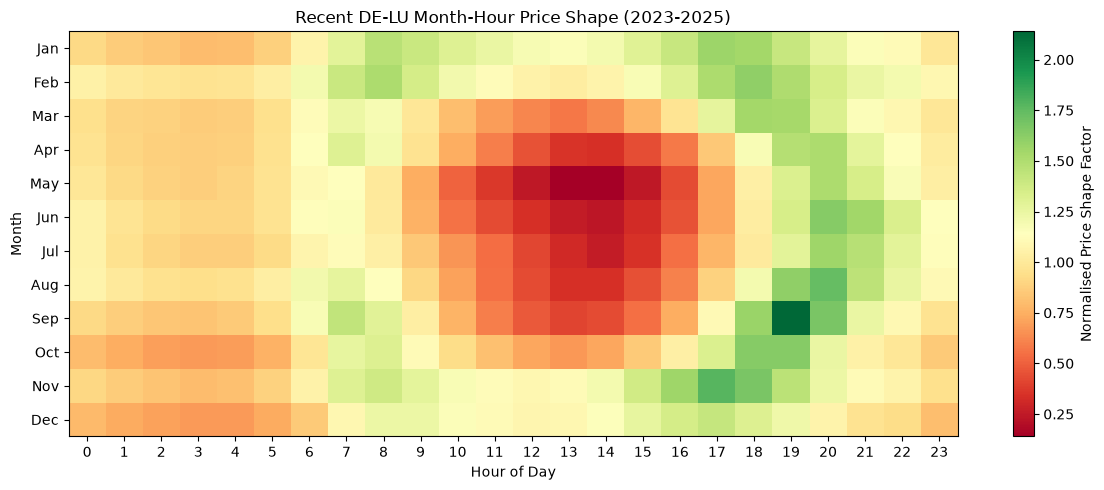

In [130]:
# Reshape the 288 factors into a month-hour matrix for visualisation
shape_matrix = (
    standard_year
    .groupby(["month", "hour"])["shape_factor"]
    .mean()
    .unstack()
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, ax = plt.subplots(figsize=(12, 5))

heatmap = ax.imshow(
    shape_matrix,
    cmap="RdYlGn",
    aspect="auto"
)

ax.set(
    title="Recent DE-LU Month-Hour Price Shape (2023-2025)",
    xlabel="Hour of Day",
    ylabel="Month",
    xticks=range(24),
    yticks=range(12)
)

ax.set_yticklabels(month_labels)

fig.colorbar(
    heatmap,
    ax=ax,
    label="Normalised Price Shape Factor"
)

fig.tight_layout()
plt.show()

### Hourly Forward Curves

The normalised price shape is now applied to each observable annual baseload forward.

For delivery year $y$:

$$
F_{y,t}^{shaped}
=
F_y^{base}
\times SF_t
$$

Because the annual average shape factor equals one:

$$
\frac{1}{8760}
\sum_{t=1}^{8760}
F_{y,t}^{shaped}
=
F_y^{base}
$$

Each shaped curve therefore preserves its corresponding annual market price while introducing the historical intraday and seasonal structure required for solar valuation.

In [131]:
shaped_forward_curves = []

# Build one 8,760-hour shaped curve for each delivery year
for year, forward_price in zip(
    forward_curve["delivery_year"],
    forward_curve["forward_price_eur_mwh"]
):

    year_curve = standard_year[
        [
            "month",
            "day",
            "hour",
            "shape_factor"
        ]
    ].copy()

    year_curve["delivery_year"] = year

    year_curve["hourly_forward_eur_mwh"] = (
        forward_price
        * year_curve["shape_factor"]
    )

    shaped_forward_curves.append(year_curve)

# Combine the five annual forward curves
shaped_forwards = pd.concat(
    shaped_forward_curves,
    ignore_index=True
)

print(
    f"Total shaped forward hours: "
    f"{len(shaped_forwards):,}"
)

Total shaped forward hours: 43,800


In [132]:
# Verify that each shaped curve preserves its annual baseload price
forward_validation = (
    shaped_forwards
    .groupby("delivery_year")
    .agg(
        shaped_average_eur_mwh=(
            "hourly_forward_eur_mwh",
            "mean"
        )
    )
    .join(
        forward_curve.set_index("delivery_year")
    )
)

forward_validation["difference_eur_mwh"] = (
    forward_validation["shaped_average_eur_mwh"]
    - forward_validation["forward_price_eur_mwh"]
)

display(
    forward_validation.round(4)
)

,shaped_average_eur_mwh,forward_price_eur_mwh,difference_eur_mwh
delivery_year,,,
2027,138.93,138.93,0.0
2028,98.55,98.55,-0.0
2029,85.54,85.54,0.0
2030,79.25,79.25,0.0
2031,75.52,75.52,0.0


The shaped forward curves reconcile exactly with the observable annual baseload futures.

The model therefore preserves the quoted annual market levels while allocating value across hours according to the recent historical DE-LU price structure.

The 2023–2025 calibration produces the base-case hourly shape. A broader 2021–2025 calibration will later be used as a sensitivity to measure the impact of the selected historical window.

## 6. Solar-Shaped Forward Value

The hourly P50 production profile is combined with each shaped forward curve to estimate the expected market value of solar generation.

For delivery year $y$, the solar-shaped forward value is:

$$
V_y^{solar}
=
\frac{
\sum_{t=1}^{8760}
F_{y,t}^{shaped} Q_t^{P50}
}{
\sum_{t=1}^{8760}
Q_t^{P50}
}
$$

The forward capture rate is then:

$$
CR_y^{forward}
=
\frac{
V_y^{solar}
}{
F_y^{base}
}
$$

A forward capture rate below 100% indicates that solar generation is concentrated in hours valued below the annual baseload forward price.

In [133]:
# Combine hourly forward prices with the P50 solar profile
#merge every forward with the unique P50 profile to get the hourly solar market value
ppa_valuation = shaped_forwards.merge(
    hourly_p50_profile[
        [
            "month",
            "day",
            "hour",
            "p50_generation_mwh"
        ]
    ],
    on=["month", "day", "hour"],
    how="left",
    validate="many_to_one"
)

# Calculate hourly solar market value
ppa_valuation["solar_market_value_eur"] = (
    ppa_valuation["hourly_forward_eur_mwh"]
    * ppa_valuation["p50_generation_mwh"]
)

print(
    f"Valuation hours: "
    f"{len(ppa_valuation):,}"
)

print(
    f"Missing production values: "
    f"{ppa_valuation['p50_generation_mwh'].isna().sum()}"
)

Valuation hours: 43,800
Missing production values: 0


In [134]:
# Aggregate hourly market value by delivery year
solar_forward_summary = (
    ppa_valuation
    .groupby("delivery_year")
    .agg(
        p50_generation_mwh=(
            "p50_generation_mwh",
            "sum"
        ),
        solar_market_value_eur=(
            "solar_market_value_eur",
            "sum"
        )
    )
)

# Calculate the generation-weighted forward value
solar_forward_summary["solar_forward_value_eur_mwh"] = (
    solar_forward_summary["solar_market_value_eur"]
    / solar_forward_summary["p50_generation_mwh"]
)

# Add annual baseload forward prices
solar_forward_summary = solar_forward_summary.join(
    forward_curve.set_index("delivery_year")
)

# Calculate relative and absolute capture effects
solar_forward_summary["forward_capture_rate_pct"] = (
    solar_forward_summary["solar_forward_value_eur_mwh"]
    / solar_forward_summary["forward_price_eur_mwh"]
    * 100
)

solar_forward_summary["capture_discount_eur_mwh"] = (
    solar_forward_summary["forward_price_eur_mwh"]
    - solar_forward_summary["solar_forward_value_eur_mwh"]
)

display(
    solar_forward_summary[
        [
            "forward_price_eur_mwh",
            "solar_forward_value_eur_mwh",
            "forward_capture_rate_pct",
            "capture_discount_eur_mwh",
            "p50_generation_mwh"
        ]
    ].round(2)
)

,forward_price_eur_mwh,solar_forward_value_eur_mwh,forward_capture_rate_pct,capture_discount_eur_mwh,p50_generation_mwh
delivery_year,,,,,
2027,138.93,101.26,72.89,37.67,105238.3
2028,98.55,71.83,72.89,26.72,105238.3
2029,85.54,62.35,72.89,23.19,105238.3
2030,79.25,57.76,72.89,21.49,105238.3
2031,75.52,55.04,72.89,20.48,105238.3


### Interpretation of the Forward Capture Rate

The model produces the same **72.89% forward capture rate** for each delivery year from 2027 to 2031.

This is a direct consequence of the modelling assumptions rather than an assumption that future capture rates will actually remain constant.

For each delivery year $y$, the hourly forward curve is constructed as:

$$
F_{y,t}^{shaped}
=
F_y^{base} \times SF_t
$$

The solar-shaped forward value is:

$$
V_y^{solar}
=
\frac{
\sum_t F_{y,t}^{shaped} Q_t^{P50}
}{
\sum_t Q_t^{P50}
}
$$

Substituting the shaped forward definition:

$$
V_y^{solar}
=
F_y^{base}
\times
\frac{
\sum_t SF_t Q_t^{P50}
}{
\sum_t Q_t^{P50}
}
$$

The forward capture rate therefore becomes:

$$
CR_y^{forward}
=
\frac{V_y^{solar}}{F_y^{base}}
=
\frac{
\sum_t SF_t Q_t^{P50}
}{
\sum_t Q_t^{P50}
}
$$

The annual baseload forward price $F_y^{base}$ cancels out.

Because the model applies the **same normalized price shape** and the **same P50 production profile** to every delivery year, the relative capture rate is identical across 2027–2031.

The absolute capture discount still changes with the forward-price level, falling from **37.67 EUR/MWh in 2027 to 20.48 EUR/MWh in 2031**.

The constant capture rate should therefore be interpreted as a **static-shape base case**, not as a forecast that solar capture conditions will remain unchanged over the five-year PPA.

## 7. Fair Fixed PPA Strike

The solar-shaped forward value differs across delivery years because the observable baseload forward curve is strongly downward sloping.

The PPA, however, is assumed to settle at a **single fixed strike price** $K$ over the full 2027–2031 delivery period.

The fair strike is the fixed price that gives the contracted solar generation the same total value as its expected market value.

Without discounting:

$$
K^{fair}
=
\frac{
\sum_y MV_y^{solar}
}{
\sum_y Q_y^{P50}
}
$$

where:

- $MV_y^{solar}$ is the expected solar market value in delivery year $y$;
- $Q_y^{P50}$ is the annual P50 generation.

Since:

$$
MV_y^{solar}
=
V_y^{solar} Q_y^{P50}
$$

the fair strike can equivalently be written as:

$$
K^{fair}
=
\frac{
\sum_y V_y^{solar} Q_y^{P50}
}{
\sum_y Q_y^{P50}
}
$$

The resulting strike converts the sequence of annual solar forward values into one fixed contractual price.

In [135]:
# Total expected solar market value over the five-year PPA
total_market_value_eur = (
    solar_forward_summary["solar_market_value_eur"].sum()
)

# Total P50 generation over the five-year PPA
total_generation_mwh = (
    solar_forward_summary["p50_generation_mwh"].sum()
)

# Calculate the undiscounted fair fixed strike
fair_strike_eur_mwh = (
    total_market_value_eur
    / total_generation_mwh
)

print(
    f"Five-year P50 generation: "
    f"{total_generation_mwh / 1_000:.2f} GWh"
)

print(
    f"Expected solar market value: "
    f"{total_market_value_eur / 1_000_000:.2f} million EUR"
)

print(
    f"Undiscounted fair PPA strike: "
    f"{fair_strike_eur_mwh:.2f} EUR/MWh"
)

Five-year P50 generation: 526.19 GWh
Expected solar market value: 36.65 million EUR
Undiscounted fair PPA strike: 69.65 EUR/MWh


### Discounted Fair Strike

The undiscounted calculation gives the same weight to market value received in 2027 and in 2031.

Because the forward curve is strongly downward sloping, the timing of cash flows matters: the high-value early delivery years should receive more present-value weight than later years.

For a discount rate $r$ and delivery year index $n_y$, the discount factor is:

$$
DF_y
=
\frac{1}{(1+r)^{n_y}}
$$

The discounted fair strike becomes:

$$
K_{disc}^{fair}
=
\frac{
\sum_y DF_y \, MV_y^{solar}
}{
\sum_y DF_y \, Q_y^{P50}
}
$$

A **3% annual discount rate** is used as an illustrative pricing assumption.

The rate accounts only for the timing of contractual cash flows and should not be interpreted as the project WACC or a complete credit-risk adjustment.

In [136]:
# Illustrative annual discount rate
discount_rate = 0.03

# 2027 is the first future delivery year
solar_forward_summary["year_index"] = (
    solar_forward_summary.index
    - 2026
)

# Calculate annual discount factors
solar_forward_summary["discount_factor"] = (
    1
    / (1 + discount_rate)
    ** solar_forward_summary["year_index"]
)

# Discount expected solar market value
solar_forward_summary["pv_market_value_eur"] = (
    solar_forward_summary["solar_market_value_eur"]
    * solar_forward_summary["discount_factor"]
)

# Discount contracted P50 generation
solar_forward_summary["pv_generation_mwh"] = (
    solar_forward_summary["p50_generation_mwh"]
    * solar_forward_summary["discount_factor"]
)

# Calculate the discounted fair strike
discounted_fair_strike_eur_mwh = (
    solar_forward_summary["pv_market_value_eur"].sum()
    / solar_forward_summary["pv_generation_mwh"].sum()
)

print(
    f"Undiscounted fair strike: "
    f"{fair_strike_eur_mwh:.2f} EUR/MWh"
)

print(
    f"Discounted fair strike: "
    f"{discounted_fair_strike_eur_mwh:.2f} EUR/MWh"
)

Undiscounted fair strike: 69.65 EUR/MWh
Discounted fair strike: 70.28 EUR/MWh


In [137]:
# Calculate annual PPA revenue at the discounted fair strike
solar_forward_summary["ppa_revenue_eur"] = (
    solar_forward_summary["p50_generation_mwh"]
    * discounted_fair_strike_eur_mwh
)

# Compare fixed PPA revenue with expected solar market value
solar_forward_summary["ppa_vs_market_eur"] = (
    solar_forward_summary["ppa_revenue_eur"]
    - solar_forward_summary["solar_market_value_eur"]
)

# Express annual values in EUR million for easier interpretation
solar_forward_summary["solar_market_value_m_eur"] = (
    solar_forward_summary["solar_market_value_eur"] / 1_000_000
)

solar_forward_summary["ppa_revenue_m_eur"] = (
    solar_forward_summary["ppa_revenue_eur"] / 1_000_000
)

solar_forward_summary["ppa_vs_market_m_eur"] = (
    solar_forward_summary["ppa_vs_market_eur"] / 1_000_000
)

display(
    solar_forward_summary[
        [
            "solar_forward_value_eur_mwh",
            "solar_market_value_m_eur",
            "ppa_revenue_m_eur",
            "ppa_vs_market_m_eur"
        ]
    ].round(2)
)

,solar_forward_value_eur_mwh,solar_market_value_m_eur,ppa_revenue_m_eur,ppa_vs_market_m_eur
delivery_year,,,,
2027,101.26,10.66,7.4,-3.26
2028,71.83,7.56,7.4,-0.16
2029,62.35,6.56,7.4,0.84
2030,57.76,6.08,7.4,1.32
2031,55.04,5.79,7.4,1.60


### Interpretation

The fixed PPA strike converts a declining sequence of annual solar forward values into one contractual price.

Because the forward curve is backwardated, the fixed PPA initially sits below the expected solar market value. In 2027, this results in a value difference of approximately **\-€3.26m**.

As forward prices decline, the relationship reverses. From 2029 onward, the fixed PPA revenue exceeds the modelled solar market value, with the difference reaching approximately **\+€1.60m in 2031**.

The PPA therefore redistributes expected value across the delivery period while providing price certainty to both counterparties.

The fair strike should not be interpreted as a forecast of future spot prices. It represents the fixed contractual price that balances the modelled forward market value of the expected solar generation profile over the full PPA period.



## 8. Risk Analysis

The fair strike represents a base-case valuation rather than a unique market truth.

Three assumptions have a material impact on the PPA economics:

1. **Price-shape calibration risk:** future hourly price patterns may differ from the recent 2023–2025 historical shape.
2. **Production risk:** actual solar generation may differ from the P50 expectation because of weather variability.
3. **Forward-price risk:** observable market prices may move before the PPA is executed.

The following sensitivities quantify the effect of these assumptions separately.

### 8.1 Price-Shape Calibration Risk

The base case uses the **2023–2025** DE-LU price shape because these years better represent the recent solar-cannibalisation regime identified in Notebook 1.

To assess the sensitivity of the valuation to this modelling choice, the same methodology is recalibrated using the broader **2021–2025** historical period.

No forward prices or production assumptions are changed.

The comparison therefore isolates the impact of the historical calibration window on:

- forward capture rate;
- solar-shaped forward value;
- fair PPA strike.

#### Calibration-Window Comparison

The calibration window affects how the annual baseload forward price is distributed across individual hours.

To illustrate the mechanism, the intraday price shape for **June** is compared under the two calibration periods:

- **2023–2025:** recent-market base case.
- **2021–2025:** broader historical sensitivity.

Both profiles are expressed relative to their respective historical average price.

A relative price factor below 1.0 indicates an hour that is valued below the overall market average, while a factor above 1.0 indicates a relatively high-value hour.

The comparison is particularly relevant for midday hours, when solar generation is highest.

In [138]:
# Build the broader 2021-2025 month-hour price shape
# assign to temporary creat month and hour variables for grouping
full_history_shape = (
    price_history
    .assign(
        month=price_history["start_date"].dt.month,
        hour=price_history["start_date"].dt.hour
    )
    .groupby(["month", "hour"])
    .agg(
        historical_price_eur_mwh=(
            "price_eur_mwh",
            "mean"
        )
    )
    .reset_index()
)

# Convert historical prices into relative price factors
full_history_average_price = (
    price_history["price_eur_mwh"].mean()
)

full_history_shape["shape_factor"] = (
    full_history_shape["historical_price_eur_mwh"]
    / full_history_average_price
)

print(
    f"2021-2025 price-shape buckets: "
    f"{len(full_history_shape)}"
)

2021-2025 price-shape buckets: 288


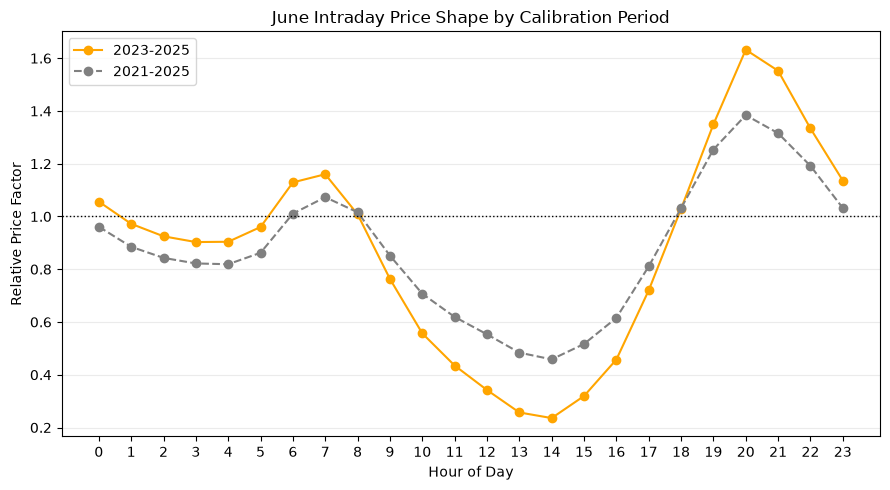

In [139]:
# Compare June price shapes
june_recent = month_hour_shape[
    month_hour_shape["month"] == 6
]

june_full = full_history_shape[
    full_history_shape["month"] == 6
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    june_recent["hour"],
    june_recent["raw_shape_factor"],
    color="orange",
    marker="o",
    label="2023-2025"
)

ax.plot(
    june_full["hour"],
    june_full["shape_factor"],
    color="grey",
    marker="o",
    linestyle="--",
    label="2021-2025"
)

# Relative average-price level
ax.axhline(
    1,
    color="black",
    linestyle=":",
    linewidth=1
)

ax.set(
    title="June Intraday Price Shape by Calibration Period",
    xlabel="Hour of Day",
    ylabel="Relative Price Factor",
    xticks=range(24)
)

ax.grid(axis="y", alpha=0.25)
ax.legend()

fig.tight_layout()
plt.show()

#### Interpretation

The recent 2023–2025 calibration shows a substantially deeper midday price depression than the broader 2021–2025 historical period.

The difference is particularly pronounced between approximately **10:00 and 16:00**, when solar generation is typically high. Around 14:00 in June, the recent relative price factor falls to approximately **0.23**, compared with approximately **0.46** under the broader historical calibration.

Conversely, the recent calibration shows a stronger evening price peak, but solar production is limited during those hours.

The recent market regime therefore shifts relative electricity value away from high\-solar hours and toward evening hours. This reduces the market value captured by a pay\-as\-produced solar profile.

The next step quantifies how this difference affects the **forward capture rate and fair PPA strike**.



#### Valuation Impact

The two calibration windows imply different relative values for solar-producing hours.

To quantify the resulting model risk, both price shapes are applied to the **same**:

- P50 hourly solar production profile;
- Cal-27 to Cal-31 baseload forward curve;
- 3% discount rate.

This ensures that any difference in capture rate or fair PPA strike is caused exclusively by the selected historical price-shape calibration.

In [140]:
# Map the 2021-2025 price shape onto the standard 8,760-hour year
full_history_year = standard_year[
    ["month", "day", "hour"]
].copy()

full_history_year = full_history_year.merge(
    full_history_shape[
        ["month", "hour", "shape_factor"]
    ],
    on=["month", "hour"],
    how="left",
    validate="many_to_one"
)

# Normalise the full 8,760-hour shape to an average of one
full_history_year["shape_factor"] = (
    full_history_year["shape_factor"]
    / full_history_year["shape_factor"].mean()
)

print(
    f"Average 2021-2025 shape factor: "
    f"{full_history_year['shape_factor'].mean():.6f}"
)

Average 2021-2025 shape factor: 1.000000


In [141]:
# Add the same P50 hourly solar production profile
full_history_year = full_history_year.merge(
    hourly_p50_profile[
        [
            "month",
            "day",
            "hour",
            "p50_generation_mwh"
        ]
    ],
    on=["month", "day", "hour"],
    how="left",
    validate="one_to_one"
)

In [142]:
# Calculate the forward capture rate under the 2021-2025 calibration
full_history_capture_rate = (
    (
        full_history_year["shape_factor"]
        * full_history_year["p50_generation_mwh"]
    ).sum()
    / full_history_year["p50_generation_mwh"].sum()
)

print(
    f"2023-2025 capture rate: "
    f"{solar_forward_summary['forward_capture_rate_pct'].iloc[0]:.2f}%"
)

print(
    f"2021-2025 capture rate: "
    f"{full_history_capture_rate * 100:.2f}%"
)

2023-2025 capture rate: 72.89%
2021-2025 capture rate: 86.25%


In [143]:
# Calculate annual solar forward values using the broader calibration
full_history_valuation = forward_curve.copy()

full_history_valuation["solar_forward_value_eur_mwh"] = (
    full_history_valuation["forward_price_eur_mwh"]
    * full_history_capture_rate
)

display(
    full_history_valuation.round(2)
)

,delivery_year,forward_price_eur_mwh,solar_forward_value_eur_mwh
0,2027,138.93,119.82
1,2028,98.55,84.99
2,2029,85.54,73.77
3,2030,79.25,68.35
4,2031,75.52,65.13


In [144]:
# Apply the same annual P50 generation
full_history_valuation["generation_mwh"] = (
    p50_generation_gwh * 1_000
)

# Calculate annual solar market value
full_history_valuation["solar_market_value_eur"] = (
    full_history_valuation["solar_forward_value_eur_mwh"]
    * full_history_valuation["generation_mwh"]
)

# Apply the same discounting assumptions as the base case
full_history_valuation["year_index"] = (
    full_history_valuation["delivery_year"]
    - 2026
)

full_history_valuation["discount_factor"] = (
    1
    / (1 + discount_rate)
    ** full_history_valuation["year_index"]
)

# Calculate the discounted fair strike
full_history_fair_strike = (
    (
        full_history_valuation["solar_market_value_eur"]
        * full_history_valuation["discount_factor"]
    ).sum()
    / (
        full_history_valuation["generation_mwh"]
        * full_history_valuation["discount_factor"]
    ).sum()
)

print(
    f"2023-2025 fair strike: "
    f"{discounted_fair_strike_eur_mwh:.2f} EUR/MWh"
)

print(
    f"2021-2025 fair strike: "
    f"{full_history_fair_strike:.2f} EUR/MWh"
)

2023-2025 fair strike: 70.28 EUR/MWh
2021-2025 fair strike: 83.16 EUR/MWh


In [145]:
# Apply the same annual P50 generation
full_history_valuation["generation_mwh"] = (
    p50_generation_gwh * 1_000
)

# Calculate annual solar market value
full_history_valuation["solar_market_value_eur"] = (
    full_history_valuation["solar_forward_value_eur_mwh"]
    * full_history_valuation["generation_mwh"]
)

# Apply the same discounting assumptions as the base case
full_history_valuation["year_index"] = (
    full_history_valuation["delivery_year"]
    - 2026
)

full_history_valuation["discount_factor"] = (
    1
    / (1 + discount_rate)
    ** full_history_valuation["year_index"]
)

# Calculate the discounted fair strike
full_history_fair_strike = (
    (
        full_history_valuation["solar_market_value_eur"]
        * full_history_valuation["discount_factor"]
    ).sum()
    / (
        full_history_valuation["generation_mwh"]
        * full_history_valuation["discount_factor"]
    ).sum()
)

print(
    f"2023-2025 fair strike: "
    f"{discounted_fair_strike_eur_mwh:.2f} EUR/MWh"
)

print(
    f"2021-2025 fair strike: "
    f"{full_history_fair_strike:.2f} EUR/MWh"
)

2023-2025 fair strike: 70.28 EUR/MWh
2021-2025 fair strike: 83.16 EUR/MWh


#### Interpretation

The price\-shape calibration window has a material impact on the PPA valuation.

Using the recent **2023–2025** market regime results in a discounted fair strike of **70.28 EUR/MWh**, compared with **83.16 EUR/MWh** when the broader **2021–2025** period is used.

The **12.88 EUR/MWh difference** is driven entirely by the hourly price shape: the solar production profile, annual forward prices and discount rate remain unchanged.

The recent calibration assigns substantially less relative value to midday hours, when solar production is highest. This reduces the forward capture rate and therefore lowers the fair PPA strike.

The result demonstrates that the historical price\-shape calibration is a material source of model risk. The **2023–2025 calibration is retained as the base case** because it better reflects the recent solar\-cannibalisation regime, while the 2021–2025 calibration is treated as a sensitivity.



### 8.2 Production Risk

The base-case valuation assumes P50 solar generation.

Actual production may differ because of interannual weather variability. The historical PVGIS weather distribution is therefore used to define three annual production scenarios:

- **P90:** conservative production level expected to be exceeded in approximately 90% of weather years.
- **P50:** central production estimate used in the base-case valuation.
- **P10:** high-production level expected to be exceeded in approximately 10% of weather years.

Using the renewable-energy probability-of-exceedance convention:

$$
E_{P90}=Q_{10\%}(E_y)
$$

$$
E_{P50}=Q_{50\%}(E_y)
$$

$$
E_{P10}=Q_{90\%}(E_y)
$$

The PPA strike is kept fixed at the base-case fair strike.

This first sensitivity therefore isolates the direct impact of annual production volume on contracted PPA revenue:

$$
R_s^{PPA}
=
K^{fair}_{base} \times E_s
$$

where $s \in \{P90,P50,P10\}$.

The hourly production shape and market-price assumptions are not changed in this first volume sensitivity.

In [146]:
# Historical annual generation distribution
annual_values = annual_generation["generation_gwh"]

# Probability-of-exceedance production scenarios
p90_generation_gwh = annual_values.quantile(0.10)
p50_generation_gwh = annual_values.quantile(0.50)
p10_generation_gwh = annual_values.quantile(0.90)

production_scenarios = pd.DataFrame({
    "scenario": ["P90", "P50", "P10"],
    "annual_generation_gwh": [
        p90_generation_gwh,
        p50_generation_gwh,
        p10_generation_gwh
    ]
})

# Keep the base-case discounted fair strike fixed
production_scenarios["ppa_strike_eur_mwh"] = (
    discounted_fair_strike_eur_mwh
)

# Calculate annual contracted revenue
production_scenarios["annual_ppa_revenue_m_eur"] = (
    production_scenarios["annual_generation_gwh"]
    * 1_000
    * production_scenarios["ppa_strike_eur_mwh"]
    / 1_000_000
)

display(
    production_scenarios.round(2)
)

,scenario,annual_generation_gwh,ppa_strike_eur_mwh,annual_ppa_revenue_m_eur
0,P90,99.15,70.28,6.97
1,P50,105.24,70.28,7.40
2,P10,114.42,70.28,8.04


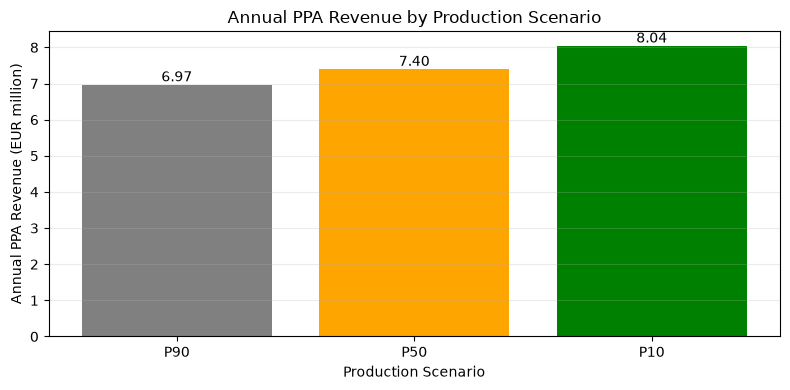

In [147]:
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    production_scenarios["scenario"],
    production_scenarios["annual_ppa_revenue_m_eur"],
    color=["grey", "orange", "green"]
)

ax.bar_label(
    bars,
    fmt="%.2f"
)

ax.set(
    title="Annual PPA Revenue by Production Scenario",
    xlabel="Production Scenario",
    ylabel="Annual PPA Revenue (EUR million)"
)

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

In [148]:
# Use P50 contracted revenue as the reference
p50_revenue = production_scenarios.loc[
    production_scenarios["scenario"] == "P50",
    "annual_ppa_revenue_m_eur"
].iloc[0]

production_scenarios["revenue_vs_p50_m_eur"] = (
    production_scenarios["annual_ppa_revenue_m_eur"]
    - p50_revenue
)

production_scenarios["revenue_vs_p50_pct"] = (
    production_scenarios["annual_ppa_revenue_m_eur"]
    / p50_revenue
    - 1
) * 100

display(
    production_scenarios[
        [
            "scenario",
            "annual_generation_gwh",
            "annual_ppa_revenue_m_eur",
            "revenue_vs_p50_m_eur",
            "revenue_vs_p50_pct"
        ]
    ].round(2)
)

,scenario,annual_generation_gwh,annual_ppa_revenue_m_eur,revenue_vs_p50_m_eur,revenue_vs_p50_pct
0,P90,99.15,6.97,-0.43,-5.79
1,P50,105.24,7.40,0.00,0.00
2,P10,114.42,8.04,0.65,8.72


#### Interpretation

Production risk remains material even under a fixed\-price pay\-as\-produced PPA.

At the base\-case strike of **70.28 EUR/MWh**, annual PPA revenue is approximately **€7.40m under P50 production**.

Under the P90 downside scenario, generation decreases to **99.15 GWh**, reducing annual revenue by approximately **€0.43m (\-5.79%)** relative to P50.

Conversely, the P10 scenario increases generation to **114.42 GWh**, resulting in approximately **€0.65m (\+8.72%)** of additional annual revenue.

The fixed\-price PPA therefore removes price uncertainty for each MWh generated, but **does not remove volume risk**. Contracted revenue remains directly dependent on the physical output of the solar asset.



### 8.3 Forward-Price Risk

The base-case PPA valuation uses the German Power Base forward curve observed at the valuation date.

Before the PPA is executed, market prices may move materially. To isolate this exposure, the entire baseload forward curve is stressed while keeping the following assumptions unchanged:

- P50 solar production profile;
- 2023–2025 hourly price shape;
- forward capture rate;
- 3% discount rate.

Three market scenarios are considered:

- **Downside:** baseload forward prices decrease by 20%.
- **Base Case:** observable forward curve.
- **Upside:** baseload forward prices increase by 20%.

For scenario $s$, the stressed annual forward price is:

$$
F_{y,s}^{base}
=
F_y^{base}(1+\Delta_s)
$$

where:

$$
\Delta_s \in \{-20\%,0,+20\%\}
$$

Because the relative hourly shape is unchanged, the sensitivity isolates the effect of the overall forward-price level on the fair PPA strike.

In [149]:
# Forward-price stress scenarios
forward_scenarios = {
    "Downside (-20%)": -0.20,
    "Base Case": 0.00,
    "Upside (+20%)": 0.20
}

forward_risk_results = []

In [150]:
# Base-case forward capture rate
base_capture_rate = (
    solar_forward_summary[
        "forward_capture_rate_pct"
    ].iloc[0]
    / 100
)

for scenario, shock in forward_scenarios.items():

    # Apply the market shock to the full annual forward curve
    scenario_curve = forward_curve.copy()

    scenario_curve["stressed_forward_eur_mwh"] = (
        scenario_curve["forward_price_eur_mwh"]
        * (1 + shock)
    )

    # Apply the unchanged solar capture rate
    scenario_curve["solar_forward_value_eur_mwh"] = (
        scenario_curve["stressed_forward_eur_mwh"]
        * base_capture_rate
    )

    # Use the same annual P50 generation
    scenario_curve["generation_mwh"] = (
        p50_generation_gwh * 1_000
    )

    # Calculate annual solar market value
    scenario_curve["solar_market_value_eur"] = (
        scenario_curve["solar_forward_value_eur_mwh"]
        * scenario_curve["generation_mwh"]
    )

    # Apply the same discount factors
    scenario_curve["year_index"] = (
        scenario_curve["delivery_year"] - 2026
    )

    scenario_curve["discount_factor"] = (
        1
        / (1 + discount_rate)
        ** scenario_curve["year_index"]
    )

    # Calculate discounted fair strike
    scenario_strike = (
        (
            scenario_curve["solar_market_value_eur"]
            * scenario_curve["discount_factor"]
        ).sum()
        / (
            scenario_curve["generation_mwh"]
            * scenario_curve["discount_factor"]
        ).sum()
    )

    forward_risk_results.append({
        "scenario": scenario,
        "forward_shock_pct": shock * 100,
        "fair_strike_eur_mwh": scenario_strike
    })

In [151]:
forward_risk_summary = pd.DataFrame(
    forward_risk_results
)

display(
    forward_risk_summary.round(2)
)

,scenario,forward_shock_pct,fair_strike_eur_mwh
0,Downside (-20%),-20.0,56.23
1,Base Case,0.0,70.28
2,Upside (+20%),20.0,84.34


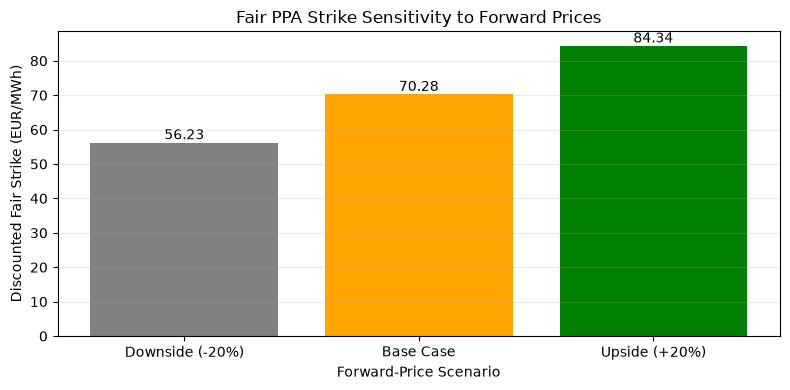

In [152]:
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    forward_risk_summary["scenario"],
    forward_risk_summary["fair_strike_eur_mwh"],
    color=["grey", "orange", "green"]
)

ax.bar_label(
    bars,
    fmt="%.2f"
)

ax.set(
    title="Fair PPA Strike Sensitivity to Forward Prices",
    xlabel="Forward-Price Scenario",
    ylabel="Discounted Fair Strike (EUR/MWh)"
)

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

#### Interpretation

The fair PPA strike is directly exposed to movements in the baseload forward curve before contract execution.

A **20% decrease** in German power forwards reduces the discounted fair strike from **70.28 EUR/MWh to 56.23 EUR/MWh**, while a **20% increase** raises it to **84.34 EUR/MWh**.

The near-proportional relationship is expected because the P50 generation profile and the 2023–2025 hourly price shape are held constant across scenarios.

This sensitivity therefore isolates **forward-price level risk**: changes in observable market prices directly affect the PPA strike that can be economically supported at execution.

## 8.4 Risk Summary

The sensitivity analysis isolates three distinct sources of PPA valuation risk.

| Risk | Base Case | Sensitivity | Main Impact |
|---|---|---|---|
| Price-shape calibration | 2023–2025 | 2021–2025 | Fair strike increases from 70.28 to 83.16 EUR/MWh |
| Production volume | P50 | P90 / P10 | Annual revenue changes by -5.79% / +8.72% |
| Forward-price level | Current forward curve | -20% / +20% | Fair strike changes to 56.23 / 84.34 EUR/MWh |

The results distinguish between risks affecting the **initial pricing of the PPA** and risks remaining **after contract execution**.

- **Price-shape calibration risk** affects the estimated market value of solar generation and therefore the fair strike.
- **Forward-price risk** affects the fair strike available at the time of execution.
- **Production risk** remains after execution because a pay-as-produced PPA fixes the price per MWh but not the number of MWh generated.

## 9. Key Findings

- The 100 MWp reference asset has a **P50 annual production of 105.24 GWh**, based on 19 historical PVGIS weather years.
- Using the recent **2023–2025 DE-LU price shape**, the model produces a **72.89% forward capture rate**, confirming a material discount relative to baseload forwards.
- The base-case discounted fair strike for the 2027–2031 pay-as-produced PPA is **70.28 EUR/MWh**.
- Price-shape calibration is a material source of model risk: using 2021–2025 instead of 2023–2025 increases the fair strike to **83.16 EUR/MWh**.
- A fixed-price pay-as-produced PPA removes price uncertainty for generated electricity but retains **weather-driven volume risk**, with P90/P10 annual revenues approximately **-5.79% / +8.72%** relative to P50.
- Before contract execution, a ±20% movement in the forward curve changes the modelled fair strike to approximately **56.23–84.34 EUR/MWh**.

Overall, the analysis shows that solar PPA valuation cannot rely on annual baseload forwards alone. The hourly production profile, forward-price shape, weather uncertainty and calibration assumptions materially affect the economic value of the contract.


## 10. Model Limitations

The model is designed as a transparent PPA valuation framework rather than a complete commercial quotation model.

The current base case does not explicitly include:

- annual PV degradation;
- plant availability and curtailment;
- balancing and route-to-market costs;
- Guarantees of Origin;
- counterparty credit and collateral;
- negative-price clauses;
- transaction costs and bid-ask spreads.

These elements would need to be incorporated before using the framework for an executable commercial offer.